 Multiple Linear Regression and Polynomial Regression



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
               MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  \
MedInc       1.000000 -0.119034  0.326895  -0.062040    0.004834  0.018766   
HouseAge    -0.119034  1.000000 -0.153277  -0.077747   -0.296244  0.013191   
AveRooms     0.326895 -0.153277  1.000000   0.847621   -0.072213 -0.004852   
AveBedrms   -0.062040 -0.077747  0.847621   1.000000   -0.066197 -0.006181   


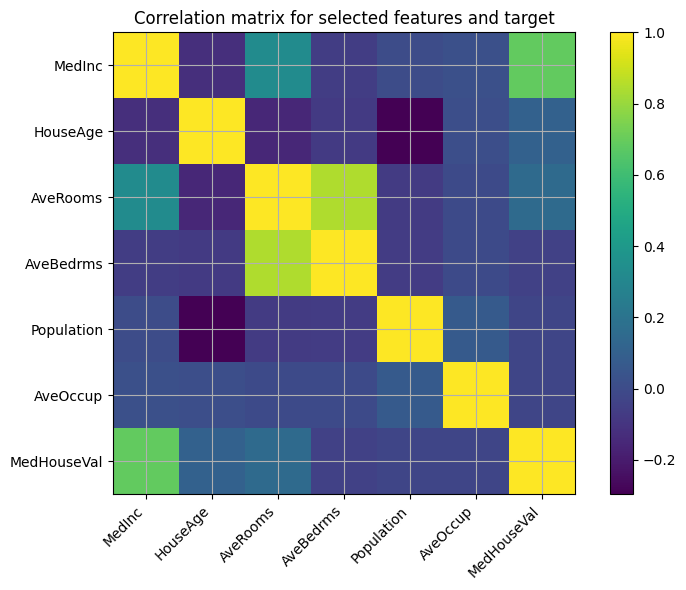

intercept(bias b/c) -0.5538716795460767
cofecient:MedInc:0.5447480332368106
cofecient:HouseAge:0.016607390111619116
cofecient:AveRooms:-0.22485574882091602
cofecient:AveBedrms:1.1298006493282446
cofecient:Population:2.356004848170362e-05
cofecient:AveOccup:-0.004523070173593642
predicted value [1.004738   1.56329627 2.67572005 2.64528652 1.98012342]
actual value [0.477   0.458   5.00001 2.186   2.78   ]
labelRegression -train
mae 0.5720624633340791
mse 0.6095938146479588
rmse 0.7807648907628716
r2 0.5431409573886778

labelRegression -test
mae 0.5748783763905292
mse 0.6287121228743695
rmse 0.7929136919453273
r2 0.5248613055247977



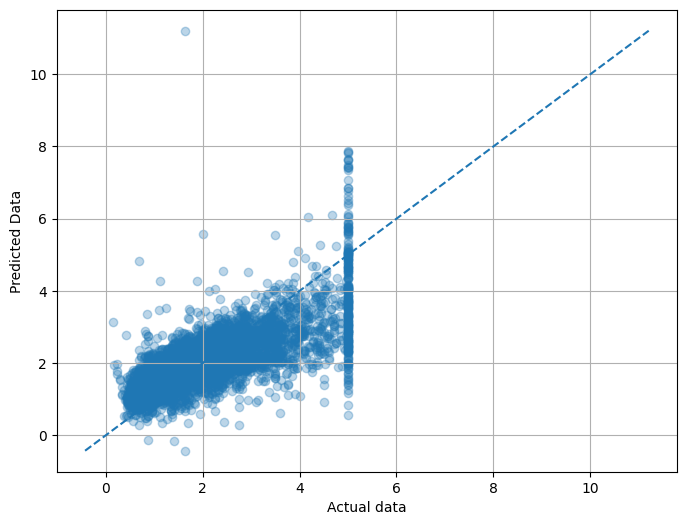

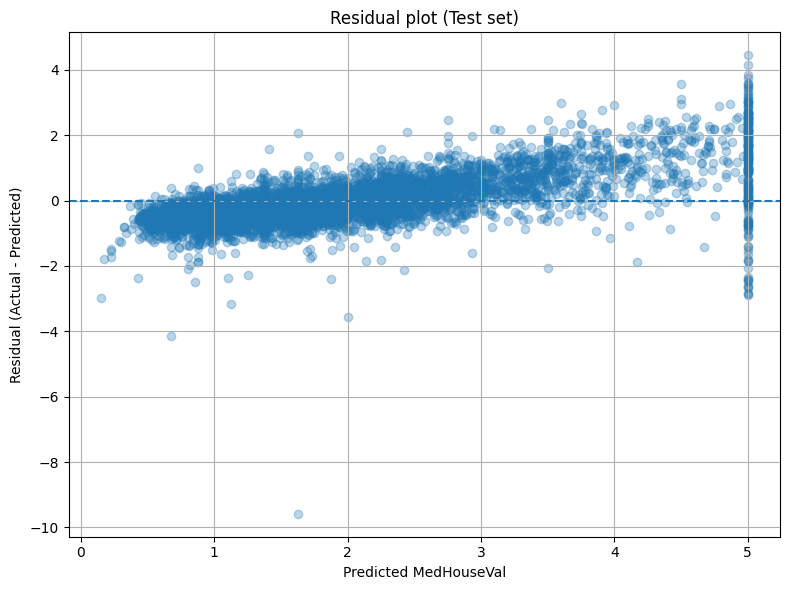

In [12]:
#1 setup import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#datasert import
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline

#configure matplotlib for slightly nicer default plots
plt.rcParams['figure.figsize']=(8,6)
plt.rcParams['axes.grid']= True

#load the california housing datasets

california= fetch_california_housing(as_frame=True)
df= california.frame.copy()
df.head(5)

#2 basic info
df.info()
df.shape
df.describe().T

# 3 featrure ans target column
target_col ='MedHouseVal'
feature_cols = ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup']

X=df[feature_cols]
y=df[target_col]

# 4 simple correlation between feature vs target
corr_matrix= df[feature_cols+ [target_col]].corr()
print(corr_matrix)
# 5 visualize correalation matrix
fig,ax= plt.subplots()
im=ax.imshow(corr_matrix.values,interpolation='nearest' )
ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.index)))
ax.set_xticklabels(corr_matrix.columns, rotation=45, ha='right')
ax.set_yticklabels(corr_matrix.index)
fig.colorbar(im)
ax.set_title('Correlation matrix for selected features and target')
plt.tight_layout()
plt.show()

# 5 train test
X_train,X_test, y_train, y_test= train_test_split(X,y, test_size=0.25, random_state=42)

#model train
lin_reg= LinearRegression()
lin_reg.fit(X_train,y_train)


#coef and intercept check
print('intercept(bias b/c)',lin_reg.intercept_)
for feature_name, coef in zip(feature_cols, lin_reg.coef_):
  print(f'cofecient:{feature_name}:{coef}')

#prediction train and test set
y_train_pred= lin_reg.predict(X_train)
y_test_pred=lin_reg.predict(X_test)

print('predicted value',y_test_pred[:5])
print('actual value',y_test.values[:5])

#create function for evaluate metrics
def regression_metrics( y_true, y_pred, label='model'):
  mae=mean_absolute_error(y_true, y_pred)
  mse=mean_squared_error(y_true, y_pred)
  rmse=np.sqrt(mse)
  r2=r2_score(y_true, y_pred)
  print(f'label{label}')
  print('mae',mae)
  print('mse',mse)
  print('rmse',rmse)
  print('r2',r2)
  print()
#evaluate train and test
regression_metrics(y_train, y_train_pred,label='Regression -train')
regression_metrics(y_test, y_test_pred,label='Regression -test')


#plot actual and predicted value for test set
plt.figure()
plt.scatter(y_test, y_test_pred, alpha=0.3)
plt.xlabel('Actual data')
plt.ylabel('Predicted Data')
#diagonal line create
min_val= min(y_test.min(),y_test_pred.min())
max_val= max(y_test.max(),y_test_pred.max())
plt.plot([min_val,max_val],[min_val,max_val], linestyle='--')
plt.show()

# Residual plot (errors = actual - predicted)
reci=y_test-y_test_pred
plt.figure()
plt.scatter(y_test,reci,alpha=0.3)
plt.axhline(0,linestyle='--')
plt.xlabel('Predicted MedHouseVal')
plt.ylabel('Residual (Actual - Predicted)')
plt.title('Residual plot (Test set)')
plt.tight_layout()
plt.show()

(15480, 1)
(5160, 1)
labelsingle feature lin_reg(test)
mae 0.6268970462646626
mse 0.7001962368292409
rmse 0.8367772922523895
r2 0.47083837938023365



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


Text(0, 0.5, 'houseval')

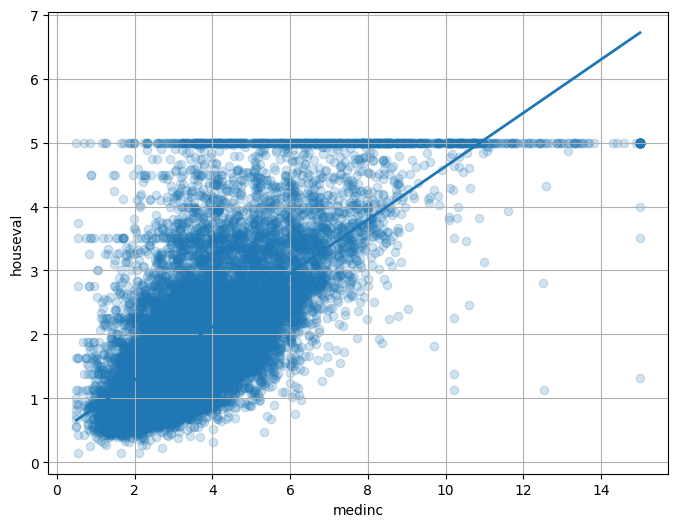

In [13]:

#prepare a single feature for illustration : MedInc vs MEdHouseVal
X_single= df[['MedInc']]
y_single= df[target_col]

X_single_train, X_single_test, y_single_train, y_single_test= train_test_split(X_single, y_single, test_size=0.25, random_state=42)
print(X_single_train.shape)
print(X_single_test.shape)

#fit a simple linear regression model using only medinc
lin_reg_single=LinearRegression()
lin_reg_single.fit(X_single_train, y_single_train)
y_single_test_pred=lin_reg_single.predict(X_single_test)

regression_metrics(y_single_test, y_single_test_pred, label='single feature lin_reg(test)')


#fisualize to single feature test
X_plot=np.linspace(X_single['MedInc'].min(), X_single['MedInc'].max(), 200 ).reshape(-1,1)
y_plot_lin=lin_reg_single.predict(X_plot)

plt.figure()
plt.scatter(X_single_train['MedInc'], y_single_train,alpha=0.2, label='train data' )
plt.plot(X_plot, y_plot_lin,linewidth=2, label='liner fit')
plt.xlabel('medinc')
plt.ylabel('houseval')